<a href="https://colab.research.google.com/github/Alinembabazi/AddMatrices-/blob/main/01_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Waste Sorter · 01 Convolutional Neural Networks

**Week 1 milestone.** Build the baseline every later approach is compared against:

- **Part A:** a small CNN trained from scratch at 128 × 128
- **Part B:** a ResNet-18 pretrained on ImageNet, fine-tuned at 224 × 224 (transfer learning)
- **Part C:** error analysis

Fill in every cell marked **TODO**; they raise `NotImplementedError` until you do.
Runtime → Change runtime type → **T4 GPU**. Run `00_setup_and_data` first.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="team_name_here")

import torch, torch.nn as nn
import matplotlib.pyplot as plt

Mounted at /content/drive
Copying data from Drive to the local disk (once per session)...
Team: team_name_here | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False


## Part A · A small CNN from scratch

**TODO 1.** Build `SmallCNN`: three blocks of `Conv2d(3×3, padding=1) → BatchNorm2d → ReLU → MaxPool2d(2)`
with 32, 64 and 128 filters, then `AdaptiveAvgPool2d(1)`, `Flatten`, `Dropout(0.3)` and a `Linear` layer
with one output per class.

Before you run it, work out by hand the shape after each block for a 3 × 128 × 128 input
(lecture: ⌊(W − K + 2P) / S⌋ + 1). Write your answer in your findings note.

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=len(ws.CLASSES)):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 3 -> 32 filters, MaxPool reduces 128x128 -> 64x64
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2: 32 -> 64 filters, MaxPool reduces 64x64 -> 32x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3: 64 -> 128 filters, MaxPool reduces 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.flat = nn.Flatten()
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.flat(x)
        x = self.dropout(x)
        return self.fc(x)

model = SmallCNN()
x = torch.randn(2, 3, 128, 128)
print("feature map shape:", tuple(model.features(x).shape), "| output:", tuple(model(x).shape))
print(f"parameters: {ws.count_params(model):.2f} M")

feature map shape: (2, 128, 16, 16) | output: (2, 6)
parameters: 0.09 M


epoch 1/15  train loss 1.372  val acc 0.488  val macro-F1 0.416
epoch 2/15  train loss 1.197  val acc 0.554  val macro-F1 0.468
epoch 3/15  train loss 1.143  val acc 0.509  val macro-F1 0.420
epoch 4/15  train loss 1.075  val acc 0.586  val macro-F1 0.497
epoch 5/15  train loss 1.053  val acc 0.628  val macro-F1 0.533
epoch 6/15  train loss 0.989  val acc 0.567  val macro-F1 0.511
epoch 7/15  train loss 0.989  val acc 0.533  val macro-F1 0.431
epoch 8/15  train loss 0.951  val acc 0.599  val macro-F1 0.550
epoch 9/15  train loss 0.928  val acc 0.639  val macro-F1 0.562
epoch 10/15  train loss 0.916  val acc 0.681  val macro-F1 0.590
epoch 11/15  train loss 0.893  val acc 0.702  val macro-F1 0.643
epoch 12/15  train loss 0.868  val acc 0.697  val macro-F1 0.647
epoch 13/15  train loss 0.857  val acc 0.694  val macro-F1 0.637
epoch 14/15  train loss 0.853  val acc 0.718  val macro-F1 0.660
epoch 15/15  train loss 0.835  val acc 0.718  val macro-F1 0.660
test accuracy 0.704 | macro-F1 0.6

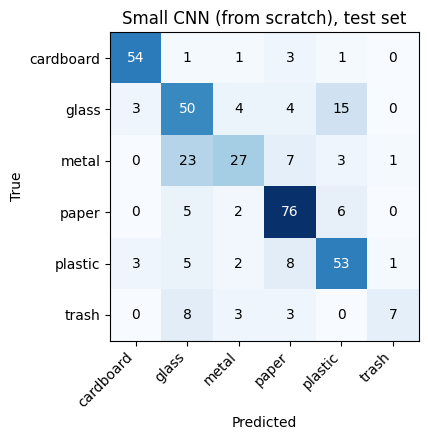

Logged: {'method': 'CNN from scratch', 'test_accuracy': '0.7045', 'test_macro_f1': '0.6681', 'trash_f1': '0.4667', 'local_accuracy': '0.2034'}


In [4]:
train_dl, val_dl, test_dl = ws.make_loaders(img_size=128, batch_size=32, augment=False)
minutes = ws.train_classifier(model, train_dl, val_dl, n_epochs=ws.epochs(15), lr=1e-3)

test = ws.evaluate(model, test_dl)
local_dl = ws.local_test_loader(128)
local = ws.evaluate(model, local_dl) if local_dl else None
print(f"test accuracy {test['accuracy']:.3f} | macro-F1 {test['macro_f1']:.3f} | trash F1 {test['trash_f1']:.3f}")
ws.plot_confusion(test, "Small CNN (from scratch), test set")
ws.log_result(1, "CNN from scratch", test, local, params_millions=ws.count_params(model), train_minutes=minutes,
              notes="SmallCNN 128px 15 epochs")

## Part B · Transfer learning with ResNet-18

**TODO 2.** Load `torchvision.models.resnet18` with ImageNet weights (`weights` is set for you) and replace
its final layer `fc` with a new `nn.Linear` that has one output per class.
Fine-tune the whole network with a small learning rate.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights
weights = None if ws.SMOKE else ResNet18_Weights.DEFAULT

def make_resnet18():
    raise NotImplementedError("TODO: write your code here")

ws.seed_everything()
resnet = make_resnet18()
train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, augment=False)
minutes = ws.train_classifier(resnet, train_dl, val_dl, n_epochs=ws.epochs(5), lr=3e-4)

test_r = ws.evaluate(resnet, test_dl)
local_dl = ws.local_test_loader(224)
local_r = ws.evaluate(resnet, local_dl) if local_dl else None
print(f"test accuracy {test_r['accuracy']:.3f} | macro-F1 {test_r['macro_f1']:.3f} | trash F1 {test_r['trash_f1']:.3f}")
ws.plot_confusion(test_r, "ResNet-18 (fine-tuned), test set")
ws.log_result(1, "ResNet-18 fine-tuned", test_r, local_r, params_millions=ws.count_params(resnet),
              train_minutes=minutes, notes="ImageNet weights 224px 5 epochs")
torch.save(resnet.state_dict(), os.path.join(ws.ROOT, "checkpoints", "resnet18_week1.pt"))

## Part C · Error analysis

**TODO 3.** Find the test images the ResNet got wrong and show up to 12 of them, each titled
`true → predicted`. Use `test_r["y_true"]`, `test_r["y_pred"]` and the `path` column of the test split.

In [ ]:
from PIL import Image
split = ws.load_split()
test_paths = split[split.split == "test"].path.tolist()
raise NotImplementedError("TODO: write your code here")


## Stretch · Data augmentation
Set `RUN_STRETCH = True` to fine-tune ResNet-18 again with random crops, flips, rotations and colour
jitter. Does it help on the TrashNet test set? On your local photos?

In [ ]:
RUN_STRETCH = False
if RUN_STRETCH:
    ws.seed_everything()
    resnet_aug = make_resnet18()
    tr_aug, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, augment=True)
    minutes = ws.train_classifier(resnet_aug, tr_aug, val_dl, n_epochs=ws.epochs(8), lr=3e-4)
    test_a = ws.evaluate(resnet_aug, test_dl)
    local_a = ws.evaluate(resnet_aug, local_dl) if local_dl else None
    ws.log_result(1, "ResNet-18 + augmentation", test_a, local_a, params_millions=ws.count_params(resnet_aug),
                  train_minutes=minutes, notes="augment 8 epochs")

## Questions for your week-1 findings note
1. Which two classes are confused most, and why might that be?
2. How much did pretraining help (accuracy, macro-F1, trash F1)? Why does it help so much on a small dataset?
3. How far does accuracy drop on your local photos? What is different about them?
4. Write the feature-map shapes you calculated for TODO 1 and check them against the printed shape.